| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week08** | Neural Networks                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | November 18, 2026, 11:55 PM                                                                                                                                                                                                                                                                                         |
| **Student Name - Number      | Edward Chisaka - 1774058                                                                                                                                                                                                                                                                                                   |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week09_ Lab implementation exercise.<br/> **Clustering**.<br/> _Hierarchical Clustering_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/08-assignment) ||

# Import libraries

In [1]:
import pandas as pd

import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

from sklearn.preprocessing import StandardScaler

# Load the dataset

In [2]:
protein = pd.read_csv("data/protein.csv", index_col=0) ## index_col=0 to use the first column as the index

print(protein.head())

                RedMeat  WhiteMeat  Eggs  Milk  Fish  Cereals  Starch  Nuts  \
Country                                                                       
Albania            10.1        1.4   0.5   8.9   0.2     42.3     0.6   5.5   
Austria             8.9       14.0   4.3  19.9   2.1     28.0     3.6   1.3   
Belgium            13.5        9.3   4.1  17.5   4.5     26.6     5.7   2.1   
Bulgaria            7.8        6.0   1.6   8.3   1.2     56.7     1.1   3.7   
Czechoslovakia      9.7       11.4   2.8  12.5   2.0     34.3     5.0   1.1   

                Fr&Veg  
Country                 
Albania            1.7  
Austria            4.3  
Belgium            4.0  
Bulgaria           4.2  
Czechoslovakia     4.0  


In [3]:
print(protein.shape)

(25, 9)


In [4]:
print(protein.info())

<class 'pandas.DataFrame'>
Index: 25 entries, Albania to Yugoslavia
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   RedMeat    25 non-null     float64
 1   WhiteMeat  25 non-null     float64
 2   Eggs       25 non-null     float64
 3   Milk       25 non-null     float64
 4   Fish       25 non-null     float64
 5   Cereals    25 non-null     float64
 6   Starch     25 non-null     float64
 7   Nuts       25 non-null     float64
 8   Fr&Veg     25 non-null     float64
dtypes: float64(9)
memory usage: 2.1 KB
None


In [5]:
print(protein.describe())

         RedMeat  WhiteMeat       Eggs       Milk       Fish    Cereals  \
count  25.000000  25.000000  25.000000  25.000000  25.000000  25.000000   
mean    9.828000   7.896000   2.936000  17.112000   4.284000  32.248000   
std     3.347078   3.694081   1.117617   7.105416   3.402533  10.974786   
min     4.400000   1.400000   0.500000   4.900000   0.200000  18.600000   
25%     7.800000   4.900000   2.700000  11.100000   2.100000  24.300000   
50%     9.500000   7.800000   2.900000  17.600000   3.400000  28.000000   
75%    10.600000  10.800000   3.700000  23.300000   5.800000  40.100000   
max    18.000000  14.000000   4.700000  33.700000  14.200000  56.700000   

          Starch       Nuts     Fr&Veg  
count  25.000000  25.000000  25.000000  
mean    4.276000   3.072000   4.136000  
std     1.634085   1.985682   1.803903  
min     0.600000   0.700000   1.400000  
25%     3.100000   1.500000   2.900000  
50%     4.700000   2.400000   3.800000  
75%     5.700000   4.700000   4.90000

# EDA and Data Preparation

In [6]:
X = protein.select_dtypes(
    include = "number"
)

print(X.head())

                RedMeat  WhiteMeat  Eggs  Milk  Fish  Cereals  Starch  Nuts  \
Country                                                                       
Albania            10.1        1.4   0.5   8.9   0.2     42.3     0.6   5.5   
Austria             8.9       14.0   4.3  19.9   2.1     28.0     3.6   1.3   
Belgium            13.5        9.3   4.1  17.5   4.5     26.6     5.7   2.1   
Bulgaria            7.8        6.0   1.6   8.3   1.2     56.7     1.1   3.7   
Czechoslovakia      9.7       11.4   2.8  12.5   2.0     34.3     5.0   1.1   

                Fr&Veg  
Country                 
Albania            1.7  
Austria            4.3  
Belgium            4.0  
Bulgaria           4.2  
Czechoslovakia     4.0  


The code extracts all numerical variables from the protein dataset and displays the first five rows. 
* `select_dtypes()`: Selects columns based on their data types.

* `include="number"`: Keeps only numerical columns (e.g., integers and floats).

* `X`: Stores the resulting DataFrame.

Useful when preparing data for statistical analysis or machine learning.

In [8]:
####--- Checking for missing values ----####
print(X.isnull().sum())

RedMeat      0
WhiteMeat    0
Eggs         0
Milk         0
Fish         0
Cereals      0
Starch       0
Nuts         0
Fr&Veg       0
dtype: int64


# Standardize the Variables

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

* Creates a `StandardScaler` object from Scikit-learn.
```shell 
scaler = StandardScaler()
```
It is used to standardize numerical variables.

```shell
X_scaled = scaler.fit_transform(X)
```

This performs two operations:

`fit()`: Calculates the mean and standard deviation of each column.

`transform()`: Standardizes each value using the formula:

Standardization ensures that variables with larger numerical values do not automatically dominate the distance calcualtions.

## Fit all Three Linkage Methods

In [11]:
'''
This calculates the hierarchical structures for all three methods.
'''

methods = [
    "single",
    "complete",
    "ward"
]

linkage_results = {}

for method in methods:
    Z = linkage(
        X_scaled,
        method = method
    )

    linkage_results[method] = Z

## Plot three dendrograms

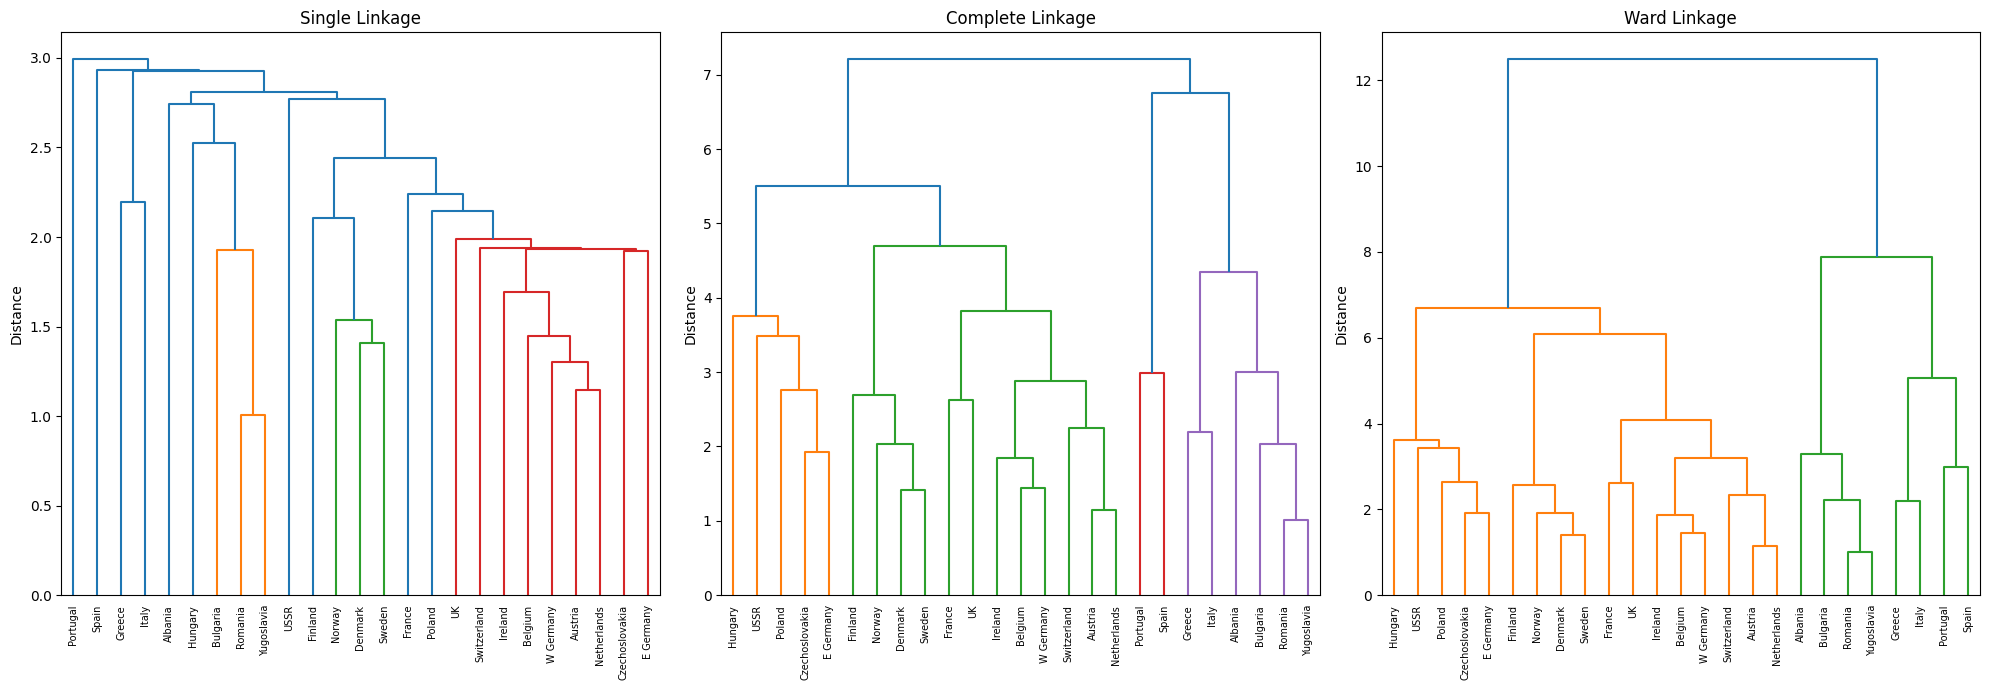

In [15]:
fig, axes = plt.subplots(
    1,3,
    figsize=(20,7)
)

for ax, method in zip(
    axes,
    methods
):
    dendrogram (
        linkage_results[method],
        labels=protein.index.tolist(),
        leaf_rotation=90,
        leaf_font_size=7,
        ax=ax
    )

    ax.set_title(
        f"{method.capitalize()} Linkage"
    )

    ax.set_ylabel("Distance")

plt.tight_layout()

plt.show()

### Comparison of the Three Hierarchical Clustering Methods

**Single linkage**

The single linkage dendrogram shows a clear chaining effect, as clusters are gradually merged at relatively small distances. Most observations are connected through a sequence of individual mergers, rather than forming clearly separated, compact groups. The maximum linkage distance is approximately 3.0, and there are no particularly large jumps in the merging distances. This suggests that single linkage tends to connect observations based on their closest neighbours, resulting in less distinct cluster boundaries.

**Complete linkage**

The complete linkage dendrogram produces more compact and clearly separated clusters compared with single linkage. Since this method considers the maximum distance between observations in two clusters, it tends to avoid the chaining effect. The dendrogram shows several distinct groups that merge at progressively higher distances. In particular, the final merging occurs at approximately 7.2, indicating a relatively clear separation between the larger clusters before they are combined. Overall, complete linkage provides a more distinct cluster structure than single linkage.

**Ward linkage**

The Ward linkage dendrogram shows the clearest separation into compact and relatively homogeneous clusters. This method minimizes the increase in within-cluster sum of squares when merging clusters. The dendrogram displays two broad groups that only merge at a relatively high distance of approximately 12.5. This large final increase in linkage distance suggests that combining these two groups would substantially increase within-cluster variation. Therefore, Ward's method appears to provide the strongest separation between the main clusters.

**Summary**

Overall, the three methods produce different clustering structures. Single linkage exhibits the strongest chaining effect, resulting in gradual merging and less clearly defined clusters. Complete linkage produces more compact groups and better separation between observations. Ward's method provides the clearest separation into larger, homogeneous clusters, as indicated by the substantial increase in linkage distance at the final merge.

Consequently, based on the three dendrograms, Ward's method appears to provide the most distinct and well-separated clustering structure, while single linkage provides the least distinct structure. Complete linkage offers an intermediate result.

# Ward Method

In [16]:
Z_ward = linkage(
    X_scaled,
    method = "ward"
)

In [17]:
'''
Inspect reasonably cut the tree 
'''
clusters = fcluster(
    Z_ward,
    t=4, ### Requesting a maximum of four clusters
    criterion="maxclust" ### use the requested maximum number of clusters
)

protein['Cluster'] = clusters 

print(protein['Cluster'].value_counts().sort_index())

Cluster
1     5
2    12
3     4
4     4
Name: count, dtype: int64


In [21]:
'''
Calculate cluster mean

The average values of the protein variables within each cluster.
'''

cluster_means = (
    protein
    .groupby("Cluster")
    .mean(numeric_only=True)
)

display(cluster_means)

,RedMeat,WhiteMeat,Eggs,Milk,Fish,Cereals,Starch,Nuts,Fr&Veg
Cluster,,,,,,,,,
1,7.920000,10.040000,2.840000,13.84,2.740000,35.740,5.560000,2.540000,4.260000
2,12.091667,9.441667,3.708333,23.00,4.991667,24.025,4.616667,1.766667,3.491667
3,7.125000,4.675000,1.200000,9.45,0.750000,51.125,1.950000,5.050000,2.975000
4,8.125000,3.800000,2.475000,11.20,7.625000,33.675,3.975000,5.675000,7.075000


## Cluster interpretation

Based on the cluster means, the four clusters show distinct dietary patterns in terms of meat, dairy, fish, cereals, and other food groups. The differences suggest that countries within each cluster have relatively similar food consumption patterns.

**Cluster 1 - Moderate and cereal-based consumption**

Cluster 1 is characterised by relatively high cereal consumption (35.74) and milk consumption (13.84). White meat (10.04) is higher than red meat (7.92), while eggs (2.84) and fish (2.74) have relatively low average values. Consumption of starch (5.56), nuts (2.54), and fruit and vegetables (4.26) is moderate.

Overall, this cluster represents a dietary pattern with a strong emphasis on cereals and dairy products, accompanied by moderate meat consumption.

**Cluster 2 - Meat and dairy-oriented consumption**

Cluster 2 has the highest average red meat consumption (12.09), as well as the highest milk consumption (23.00). It also has relatively high fish (4.99) and egg consumption (3.71). However, cereal consumption (24.03) is lower than in the other clusters, while nuts (1.77) and fruit and vegetables (3.49) are relatively low.

Overall, this cluster is characterised by a stronger emphasis on animal-based food products, particularly red meat and dairy products.

**Cluster 3 - Cereal and nut-oriented consumption**

Cluster 3 stands out because it has the highest cereal consumption (51.13), considerably exceeding the other clusters. It also has relatively high nut consumption (5.05). In contrast, it has the lowest average consumption of eggs (1.20), fish (0.75), and starch (1.95). Milk consumption (9.45) is also relatively low, as is fruit and vegetable consumption (2.98).

Overall, this cluster represents a dietary pattern strongly dominated by cereals and nuts, with comparatively low consumption of animal-based products.

**Cluster 4 - Fish, vegetables and nuts-oriented consumption**

Cluster 4 has the highest average fish consumption (7.63), fruit and vegetable consumption (7.08), and nut consumption (5.68). It also has relatively high cereal consumption (33.68). However, white meat consumption (3.80) is the lowest among all four clusters, while red meat consumption (8.13) is moderate.

Overall, this cluster is characterised by a greater emphasis on fish, fruit and vegetables, and nuts, suggesting a more varied dietary pattern.

**Summary**

| Cluster | Main characteristics |
| --- | --- |
| 1 | Higher cereals, milk and white meat |
| 2 | Higher red meat, milk, fish and eggs |
| 3 | Very high cereals and relatively high nuts |
| 4 | Higher fish, fruit and vegetables, and nuts |

The results suggest that countries within the same cluster share similarities in their food consumption habits. Some clusters place greater emphasis on animal-based products, while others are more strongly characterised by cereals, nuts, fish, or plant-based foods.

These differences could potentially reflect regional or cultural dietary preferences. 

_My Take_

_However, without examining the actual country membership of each cluster, it would not be appropriate to assign specific geographical or cultural characteristics to the groups_.

## Method comparison and conclusion

Single linkage produced a chaining effect, with countries gradually merging into larger clusters and relatively little separation between groups. Complete linkage resulted in more compact clusters and clearer separation. Ward's method produced the clearest separation between the main groups, with a substantial increase in linkage distance at the final merge.

Based on the dendrograms, Ward's method was considered the most interpretable approach because it produced relatively compact and well-separated clusters.

The four clusters obtained show distinct nutritional patterns. Cluster 1 is characterised by cereals and milk, Cluster 2 by red meat and dairy products, Cluster 3 by cereals and nuts, and Cluster 4 by fish, fruit and vegetables, and nuts. Overall, Ward's method provides a useful way of identifying similarities and differences in food consumption patterns across countries.